# 04 — Decisão, explicação e teste

Usa o LightGBM escolhido em `03_modelos.ipynb` (salvo em `models/`), treinado só no período de treino.
1. **4.1** — escolher o limiar de decisão pelo custo, na validação.
2. **4.2** — entender o que o modelo usa.
3. **4.3** — avaliar no teste, uma vez só, com tudo já decidido.

In [1]:
import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.base import clone
from sklearn.metrics import confusion_matrix

import graficos
from avaliacao import metricas, metricas_de_acerto, nota_da_tabela

graficos.aplicar_estilo()

modelo = joblib.load("../models/lightgbm.joblib")
validacao = pd.read_parquet("../data/processed/validacao.parquet")

y_validacao = validacao["is_canceled"].to_numpy()
prob_validacao = modelo.predict_proba(validacao[modelo.feature_names_in_])[:, 1]

## 4.1 Limiar de decisão pelo custo

O modelo dá uma probabilidade, mas o hotel precisa de um sim ou não: contatar ou não esta reserva. O corte (limiar) não deve ser 0,5 por padrão — ele depende de quanto custa errar para cada lado.

**Cenário** (suposição, para ser trocada pelos números reais do hotel):
- A ação é contatar a reserva e oferecer um incentivo para confirmar (por exemplo, upgrade ou desconto). Custa **€30 por reserva contatada** — inclusive nas que não iam cancelar.
- Quando a reserva ia mesmo cancelar, o contato **recupera 25% do valor da reserva** (diária × noites): em parte dos casos o hóspede mantém a reserva ou o quarto é revendido a tempo.

Lucro de um limiar = 25% do valor das reservas contatadas que iam cancelar − €30 × reservas contatadas.

*A base não informa a moeda; como os hotéis são em Portugal, os valores são tratados como euro.*

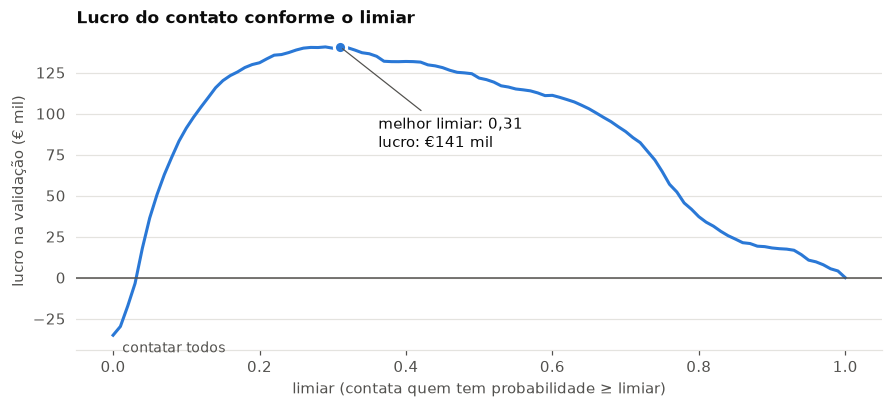

In [2]:
CUSTO_CONTATO = 30  # € por reserva contatada
RECUPERACAO = 0.25  # fração do valor recuperada quando a reserva ia cancelar

def valor_da_reserva(base):
    """Diária × noites."""
    return (base["adr"] * (base["stays_in_weekend_nights"] + base["stays_in_week_nights"])).to_numpy()


def lucro(contatar, y, valor, custo=CUSTO_CONTATO, recuperacao=RECUPERACAO):
    """Lucro de contatar as reservas marcadas em `contatar` (array de True/False)."""
    ganho = (y[contatar] * recuperacao * valor[contatar]).sum()
    return ganho - custo * contatar.sum()


valor_validacao = valor_da_reserva(validacao)
limiares = np.round(np.arange(0, 1.0001, 0.01), 2)
curva = pd.Series([lucro(prob_validacao >= t, y_validacao, valor_validacao) for t in limiares], index=limiares)
melhor = curva.idxmax()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(curva.index, curva / 1000, color=graficos.AZUL, linewidth=2)
ax.axhline(0, color=graficos.TEXTO_SECUNDARIO, linewidth=1)
ax.plot(melhor, curva[melhor] / 1000, "o", color=graficos.AZUL, markersize=8, markeredgecolor="white", markeredgewidth=2)
ax.annotate(f"melhor limiar: {melhor:.2f}\nlucro: €{curva[melhor] / 1000:.0f} mil".replace(".", ","),
            (melhor, curva[melhor] / 1000), xytext=(25, -45), textcoords="offset points", va="top",
            arrowprops=dict(arrowstyle="-", color=graficos.TEXTO_SECUNDARIO, linewidth=0.8))
ax.annotate("contatar todos", (0, curva[0] / 1000), xytext=(6, -4), textcoords="offset points", va="top",
            color=graficos.TEXTO_SECUNDARIO, fontsize=9)
ax.set_xlabel("limiar (contata quem tem probabilidade ≥ limiar)")
ax.set_ylabel("lucro na validação (€ mil)")
ax.set_title("Lucro do contato conforme o limiar")
plt.show()

**Comparando estratégias** — quantas reservas são contatadas, quantas delas iam cancelar de fato, quantos dos cancelamentos são alcançados e o lucro.

In [3]:
def comparar_estrategias(prob, y, valor, limiar):
    """Para cada estratégia: quantas reservas são contatadas, quantas delas iam cancelar,
    quantos dos cancelamentos são alcançados e o lucro."""
    estrategias = {
        "não contatar ninguém": np.zeros(len(prob), dtype=bool),
        "contatar todos": np.ones(len(prob), dtype=bool),
        "top 10%": prob >= np.quantile(prob, 0.90),
        "limiar padrão 0,5": prob >= 0.5,
        f"limiar escolhido {limiar:.2f}".replace(".", ","): prob >= limiar,
    }
    return pd.DataFrame({
        nome: {
            "% contatadas": contatar.mean(),
            "das contatadas, iam cancelar": y[contatar].mean() if contatar.any() else np.nan,
            "dos cancelamentos, alcançados": y[contatar].sum() / y.sum(),
            "lucro (€ mil)": lucro(contatar, y, valor) / 1000,
        }
        for nome, contatar in estrategias.items()
    }).T.round(3)


comparar_estrategias(prob_validacao, y_validacao, valor_validacao, melhor)

,% contatadas,"das contatadas, iam cancelar","dos cancelamentos, alcançados",lucro (€ mil)
não contatar ninguém,0.000,NaN,0.000,0.000
contatar todos,1.000,0.284,1.000,-35.103
top 10%,0.100,0.741,0.260,85.469
"limiar padrão 0,5",0.186,0.684,0.448,121.650
"limiar escolhido 0,31",0.306,0.588,0.632,140.748


Com o limiar 0,31, o hotel contata 31% das reservas; 59% delas iam cancelar, e o contato alcança 63% de todos os cancelamentos. O lucro é de **€141 mil** nos 4 meses da validação, contra €122 mil com o limiar padrão 0,5, €85 mil contatando só o top 10% e **prejuízo** de €35 mil contatando todo mundo.

A curva é achatada perto do topo: entre ~0,22 e ~0,36 o lucro fica a menos de 5% do máximo, então o valor exato do limiar não é crítico. Como o limiar foi escolhido nesses mesmos dados, o lucro da validação é otimista — o número honesto vem do teste (4.3).

**O limiar muda se o cenário mudar.** Melhor limiar para outros custos de contato e taxas de recuperação:

In [4]:
def melhor_limiar(custo, recuperacao):
    return max(limiares, key=lambda t: lucro(prob_validacao >= t, y_validacao, valor_validacao, custo, recuperacao))


pd.DataFrame({
    f"recupera {r:.0%}": {f"contato €{c}": melhor_limiar(c, r) for c in [10, 20, 30, 40]}
    for r in [0.10, 0.25, 0.50]
})

,recupera 10%,recupera 25%,recupera 50%
contato €10,0.22,0.11,0.08
contato €20,0.44,0.18,0.11
contato €30,0.72,0.31,0.15
contato €40,0.81,0.42,0.18


Com contato barato (€10) e boa recuperação, vale contatar quase todo mundo (limiar 0,08); com contato caro (€40) e pouca recuperação, só as reservas de risco altíssimo (0,81). **O modelo dá a nota; o custo do negócio decide o corte.** Daqui em diante fica o cenário base (€30 e 25%) e o limiar 0,31.

## 4.2 O que o modelo usa

**SHAP** calcula, para cada reserva, quanto cada variável empurrou a nota do modelo para cima ou para baixo em relação à nota média. Positivo aumenta o risco de cancelar; negativo diminui. A escala é a interna do modelo (*log-odds*): +1 multiplica a chance de cancelar por cerca de 2,7.

O próprio LightGBM calcula os valores SHAP (`pred_contrib=True`). Como no preparo cada categoria virou várias colunas 0/1, os valores dessas colunas são somados de volta na variável original.

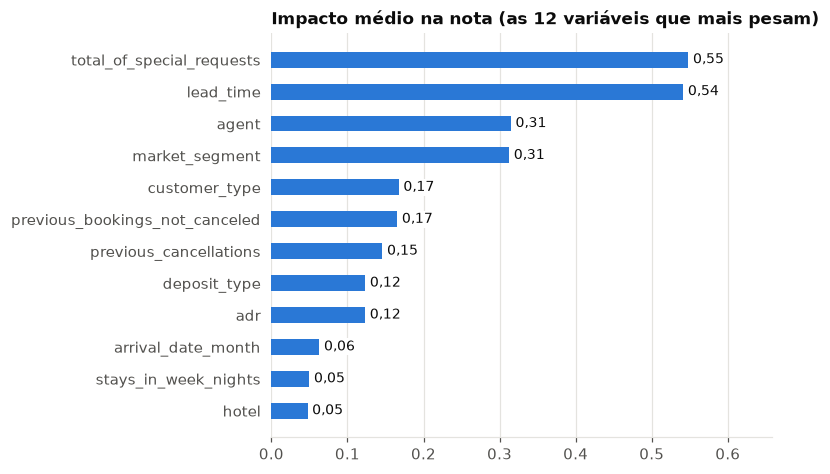

In [5]:
preparo, lgbm = modelo[0], modelo[-1]
X_validacao = validacao[modelo.feature_names_in_]

dados_preparados = preparo.transform(X_validacao)
if sparse.issparse(dados_preparados):
    dados_preparados = dados_preparados.toarray()

# a última coluna é a nota média (ponto de partida); as outras são o efeito de cada coluna do preparo
contribuicoes = lgbm.predict(dados_preparados, pred_contrib=True)[:, :-1]


def variavel_original(coluna_preparo):
    """'categoricas__market_segment_Online TA' -> 'market_segment'; 'numericas__lead_time' -> 'lead_time'."""
    bloco, resto = coluna_preparo.split("__", 1)
    if bloco == "numericas":
        return resto
    return next(c for c in modelo.feature_names_in_ if resto.startswith(c + "_"))


nomes = [variavel_original(c) for c in preparo.get_feature_names_out()]
shap_por_variavel = pd.DataFrame(contribuicoes, columns=nomes).T.groupby(level=0).sum().T

importancia = shap_por_variavel.abs().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.2))
graficos.barras_horizontais(ax, importancia.head(12), "Impacto médio na nota (as 12 variáveis que mais pesam)",
                            formato=lambda v: f"{v:.2f}".replace(".", ","))
plt.show()

**Para que lado cada variável empurra.** Efeito médio na nota por faixa ou categoria, nas quatro variáveis mais importantes para a história (laranja aumenta o risco, azul diminui).

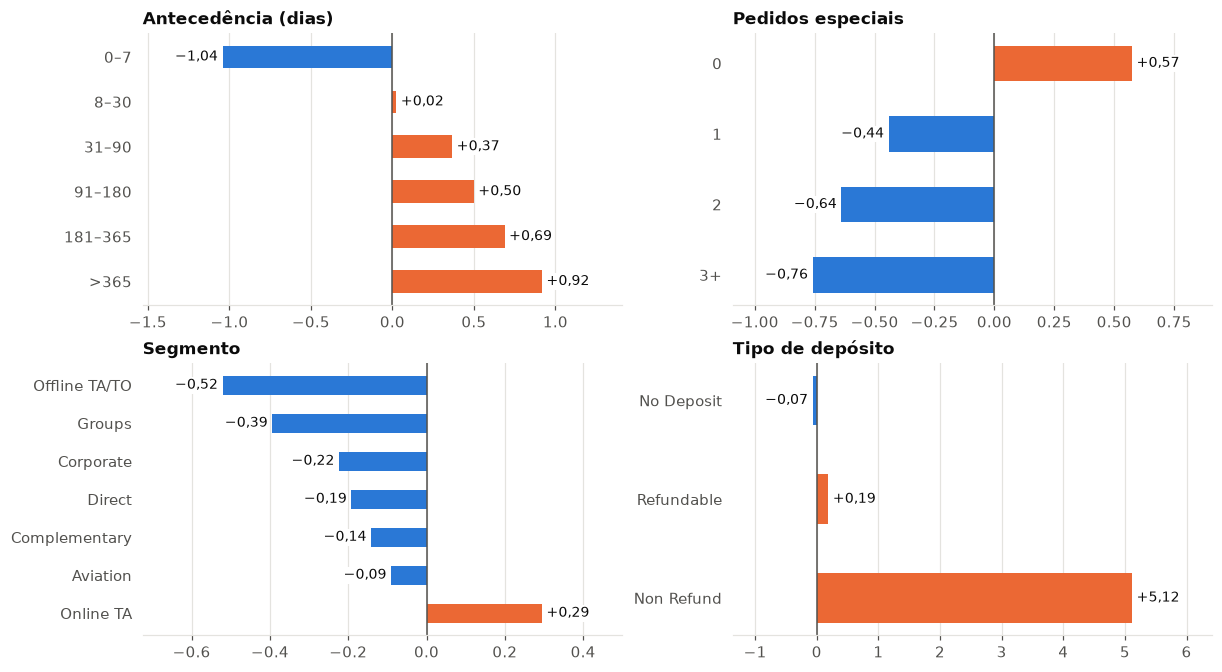

In [6]:
faixas = pd.cut(X_validacao["lead_time"], [-1, 7, 30, 90, 180, 365, np.inf],
                labels=["0–7", "8–30", "31–90", "91–180", "181–365", ">365"])
pedidos = X_validacao["total_of_special_requests"].clip(upper=3).astype(str).replace({"3": "3+"})

efeitos = {
    "Antecedência (dias)": shap_por_variavel["lead_time"].groupby(faixas, observed=True).mean(),
    "Pedidos especiais": shap_por_variavel["total_of_special_requests"].groupby(pedidos).mean(),
    "Segmento": shap_por_variavel["market_segment"].groupby(X_validacao["market_segment"]).mean().sort_values(),
    "Tipo de depósito": shap_por_variavel["deposit_type"].groupby(X_validacao["deposit_type"]).mean().sort_values(),
}

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, (titulo, valores) in zip(axes.flat, efeitos.items()):
    graficos.barras_com_sinal(ax, valores, titulo)
fig.savefig("../figures/efeito_das_variaveis.png", dpi=150, bbox_inches="tight")
plt.show()

**Faz sentido de negócio?**
- **Antecedência:** quanto mais cedo a reserva, mais risco — de −1,0 na última semana a +0,9 com mais de um ano. É o mesmo padrão da EDA.
- **Pedidos especiais:** reserva sem nenhum pedido ganha +0,6; com pedidos, a nota cai. Quem pede cama de casal ou andar alto está comprometido com a viagem.
- **Segmento:** agências online aumentam o risco; operadoras, grupos e empresas diminuem.
- **Depósito:** `Non Refund` pesa muito (+5) — o modelo aprendeu o padrão dos bloqueios de grupo que vimos na auditoria. São poucas reservas (158 na validação), mas quase todas canceladas.
- Fora do gráfico: quem já cancelou antes tem efeito forte (+2,9), mas são só 136 reservas na validação.

As direções batem com o que a EDA mostrou. O ponto de atenção é a variável **mais importante**: pedidos especiais. Na auditoria ela ficou com uma ressalva — o total pode incluir pedidos feitos depois da reserva, perto da chegada, por quem de fato vai aparecer.

**Teste de robustez: e sem os pedidos especiais?** O mesmo modelo, treinado de novo com a variável zerada (uma coluna constante não carrega informação, então é o mesmo que tirá-la).

In [7]:
treino = pd.read_parquet("../data/processed/treino.parquet")
X_treino = treino[modelo.feature_names_in_]

sem_pedidos = clone(modelo).fit(X_treino.assign(total_of_special_requests=0), treino["is_canceled"])
prob_sem_pedidos = sem_pedidos.predict_proba(X_validacao.assign(total_of_special_requests=0))[:, 1]

pd.DataFrame({
    "com pedidos especiais": metricas(y_validacao, prob_validacao),
    "sem pedidos especiais": metricas(y_validacao, prob_sem_pedidos),
}).T.round(3)

,ROC-AUC,PR-AUC,cancelam no top 10%
com pedidos especiais,0.815,0.647,0.741
sem pedidos especiais,0.789,0.589,0.656


Sem a variável, o ROC-AUC cai de 0,815 para 0,789 e o top 10% de 74% para 66%. Ou seja, boa parte do desempenho vem dela. Se parte dos pedidos for registrada depois da reserva, o desempenho real no momento da reserva fica **entre os dois números**: 66% é o cenário conservador, 74% o otimista.

## 4.3 Resultado final no teste

Tudo foi decidido antes de abrir o teste: o modelo (LightGBM com a configuração do notebook 03), o limiar (0,31) e o cenário de custo (€30 por contato, 25% de recuperação). O teste — chegadas de mai a ago/2017 — é usado agora, uma vez. Nada é ajustado depois disso.

Como combinado na 4.2, aparecem os dois modelos: o principal (otimista) e o sem pedidos especiais (conservador).

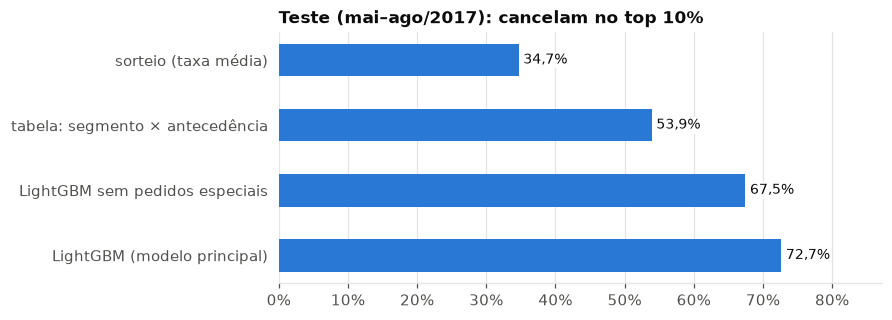

,ROC-AUC,PR-AUC,cancelam no top 10%
sorteio (taxa média),0.500,0.347,0.347
tabela: segmento × antecedência,0.675,0.475,0.539
LightGBM sem pedidos especiais,0.745,0.597,0.675
LightGBM (modelo principal),0.765,0.633,0.727


In [8]:
teste = pd.read_parquet("../data/processed/teste.parquet")
X_teste, y_teste = teste[modelo.feature_names_in_], teste["is_canceled"].to_numpy()

prob_teste = modelo.predict_proba(X_teste)[:, 1]
prob_teste_sem_pedidos = sem_pedidos.predict_proba(X_teste.assign(total_of_special_requests=0))[:, 1]

notas = {
    "sorteio (taxa média)": np.full(len(y_teste), treino["is_canceled"].mean()),
    "tabela: segmento × antecedência": nota_da_tabela(X_treino, treino["is_canceled"], X_teste),
    "LightGBM sem pedidos especiais": prob_teste_sem_pedidos,
    "LightGBM (modelo principal)": prob_teste,
}
resultado_teste = pd.DataFrame({nome: metricas(y_teste, nota) for nome, nota in notas.items()}).T

fig, ax = plt.subplots(figsize=(8, 2.8))
graficos.barras_horizontais(ax, resultado_teste["cancelam no top 10%"], "Teste (mai–ago/2017): cancelam no top 10%")
fig.savefig("../figures/resultado_teste.png", dpi=150, bbox_inches="tight")
plt.show()

resultado_teste.round(3)

- **O modelo principal mantém o desempenho no que importa:** 73% de acerto no top 10% (74% na validação), contra 54% da tabela e 35% sorteando. A versão conservadora, sem pedidos especiais, fica em 67%.
- **O ROC-AUC caiu** de 0,815 na validação para 0,765 no teste. O verão de 2017 é um período diferente do que o modelo viu (mais cancelamentos, reservas mais caras), e a ordenação fica menos precisa no meio da lista — mas o topo, que é onde o hotel age, continua bom.

**O nível das probabilidades** — o modelo prevê, em média, a taxa de cancelamento certa?

In [9]:
print(f"Probabilidade média prevista no teste: {graficos.pct(prob_teste.mean())}")
print(f"Taxa real de cancelamento no teste:     {graficos.pct(y_teste.mean())}")

Probabilidade média prevista no teste: 28,8%
Taxa real de cancelamento no teste:     34,7%


Não: o modelo aprendeu num período em que 25% das reservas cancelavam, e no teste foram 35%. Ele continua sabendo **quem** é mais arriscado, mas subestima **quanto**. Em produção, isso pede retreino periódico com os dados mais recentes.

**A decisão no teste** — as mesmas estratégias da 4.1, com o limiar 0,31 escolhido na validação.

In [10]:
valor_teste = valor_da_reserva(teste)
print(f"Valor médio de uma reserva — validação: €{valor_validacao.mean():.0f} | teste: €{valor_teste.mean():.0f}")

comparar_estrategias(prob_teste, y_teste, valor_teste, melhor)

Valor médio de uma reserva — validação: €313 | teste: €561


,% contatadas,"das contatadas, iam cancelar","dos cancelamentos, alcançados",lucro (€ mil)
não contatar ninguém,0.000,NaN,0.000,0.000
contatar todos,1.000,0.347,1.000,450.992
top 10%,0.100,0.727,0.209,165.764
"limiar padrão 0,5",0.205,0.679,0.402,300.916
"limiar escolhido 0,31",0.306,0.618,0.545,422.829


O limiar 0,31 dá **€423 mil** de lucro nos 4 meses de teste — mas **contatar todo mundo daria €451 mil**. O limiar fixo, escolhido com os dados de jan–abr, **não sobreviveu à mudança de temporada**: no verão as reservas valem quase o dobro (€561 contra €313, diárias e estadias maiores) e cancelam mais, então o contato compensa até nas reservas de risco mais baixo.

**Aprendizado — análise feita depois de ver o teste, não é o resultado oficial.** O problema é usar um corte fixo de probabilidade sem olhar o valor de cada reserva. Uma regra que sai direto do cenário de custo, sem nada ajustado nos dados: contatar quando *probabilidade × 25% × valor da reserva > €30* — ou seja, quando o ganho esperado paga o contato.

In [11]:
def regra_valor_esperado(prob, valor):
    """Contata quando o ganho esperado (probabilidade × recuperação × valor) paga o custo do contato."""
    return prob * RECUPERACAO * valor > CUSTO_CONTATO


periodos = {
    "validação": (prob_validacao, y_validacao, valor_validacao),
    "teste": (prob_teste, y_teste, valor_teste),
}
pd.DataFrame({
    nome: {
        "contatar todos": lucro(np.ones(len(prob), dtype=bool), y, valor) / 1000,
        f"limiar fixo {melhor:.2f}".replace(".", ","): lucro(prob >= melhor, y, valor) / 1000,
        "regra do valor esperado": lucro(regra_valor_esperado(prob, valor), y, valor) / 1000,
    }
    for nome, (prob, y, valor) in periodos.items()
}).round(0).rename_axis("lucro (€ mil)")

,validação,teste
lucro (€ mil),,
contatar todos,-35.0,451.0
"limiar fixo 0,31",141.0,423.0
regra do valor esperado,166.0,569.0


A regra do valor esperado ganha nos dois períodos — inclusive na validação, onde ela poderia ter sido escolhida — e se ajusta sozinha à temporada: no verão, com reservas mais caras, ela contata mais gente. É a recomendação para uma próxima versão, junto com o retreino periódico.

## 4.4 Taxa de acerto: acurácia, precisão, recall e F1

Até aqui o foco foi ordenar as reservas (ROC-AUC, top 10%). Mas a pergunta mais comum é *quanto o modelo acerta?* Para responder, a probabilidade vira sim/não com um limiar, e a previsão é comparada com o que aconteceu:
- **Acurácia:** a fração de reservas classificadas certo, cancelando ou não.
- **Precisão:** das reservas que o modelo diz que vão cancelar, quantas cancelam.
- **Recall:** dos cancelamentos que aconteceram, quantos o modelo pegou.
- **F1:** a média harmônica de precisão e recall. Só fica alta se as duas forem boas ao mesmo tempo.

Primeiro, como cada uma muda com o limiar — na validação, onde as escolhas são feitas.

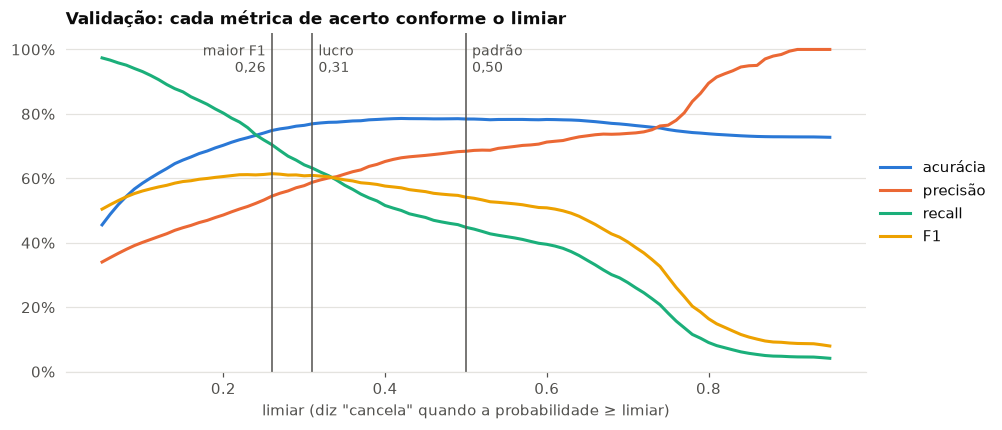

In [12]:
limiares_acerto = np.round(np.arange(0.05, 0.96, 0.01), 2)
curvas = pd.DataFrame([metricas_de_acerto(y_validacao, prob_validacao >= t) for t in limiares_acerto], index=limiares_acerto)
limiar_f1 = curvas["F1"].idxmax()

fig, ax = plt.subplots(figsize=(9, 3.8))
for (nome, serie), cor in zip(curvas.items(), graficos.CORES):
    ax.plot(serie.index, serie, color=cor, linewidth=2, label=nome)
# rótulo à esquerda da linha do F1 e à direita das outras, para não se encostarem
for limiar, rotulo, lado in [(limiar_f1, "maior F1", "right"), (melhor, "lucro", "left"), (0.5, "padrão", "left")]:
    ax.axvline(limiar, color=graficos.TEXTO_SECUNDARIO, linewidth=1)
    ax.annotate(f"{rotulo}\n{limiar:.2f}".replace(".", ","), (limiar, 1.02), xytext=(-4 if lado == "right" else 4, 0),
                textcoords="offset points", ha=lado, va="top", fontsize=9, color=graficos.TEXTO_SECUNDARIO)
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("limiar (diz \"cancela\" quando a probabilidade ≥ limiar)")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title("Validação: cada métrica de acerto conforme o limiar")
fig.savefig("../figures/metricas_por_limiar.png", dpi=150, bbox_inches="tight")
plt.show()

- Baixar o limiar faz o modelo dizer "cancela" mais vezes: o **recall** sobe e a **precisão** cai.
- A **acurácia** quase não se mexe entre 0,3 e 0,6 (fica perto de 77–79%): ela é dominada pelas reservas que não cancelam, que são a maioria.
- O **F1** é máximo em 0,26, perto do limiar do lucro (0,31). O limiar padrão 0,5 é o pior dos três para F1.

Cada métrica aponta para um limiar diferente; qual usar depende da decisão. Para o hotel, o critério é o lucro (4.1). O limiar de maior F1 entra abaixo só para comparação — também escolhido só na validação.

**No teste** — o modelo nos três limiares, contra dois chutes.

In [13]:
previsoes_teste = {
    "chutar sempre 'não cancela'": np.zeros(len(y_teste), dtype=bool),
    "chutar sempre 'cancela'": np.ones(len(y_teste), dtype=bool),
    "LightGBM, limiar padrão 0,5": prob_teste >= 0.5,
    f"LightGBM, limiar do lucro {melhor:.2f}".replace(".", ","): prob_teste >= melhor,
    f"LightGBM, limiar de maior F1 {limiar_f1:.2f}".replace(".", ","): prob_teste >= limiar_f1,
}
pd.DataFrame({nome: metricas_de_acerto(y_teste, previsto) for nome, previsto in previsoes_teste.items()}).T.round(3)

,acurácia,precisão,recall,F1
chutar sempre 'não cancela',0.653,0.000,0.000,0.000
chutar sempre 'cancela',0.347,0.347,1.000,0.515
"LightGBM, limiar padrão 0,5",0.727,0.679,0.402,0.505
"LightGBM, limiar do lucro 0,31",0.725,0.618,0.545,0.579
"LightGBM, limiar de maior F1 0,26",0.714,0.582,0.628,0.604


- **Acurácia de 72–73%** em qualquer limiar — parece bom, mas chutar que ninguém cancela já acerta 65,3%. O ganho real em acurácia é de uns 7 pontos.
- **O F1 mostra o problema do limiar 0,5:** com recall de só 40%, o F1 (0,505) fica **abaixo** do chute de que todas cancelam (0,515). Com o limiar do lucro sobe para 0,58, e com o de maior F1 para 0,60.
- O limiar do lucro fica no meio: acerta 62% das reservas que marca (precisão) e pega 55% dos cancelamentos (recall).

**Matriz de confusão no teste** — com o limiar do lucro, que é o oficial.

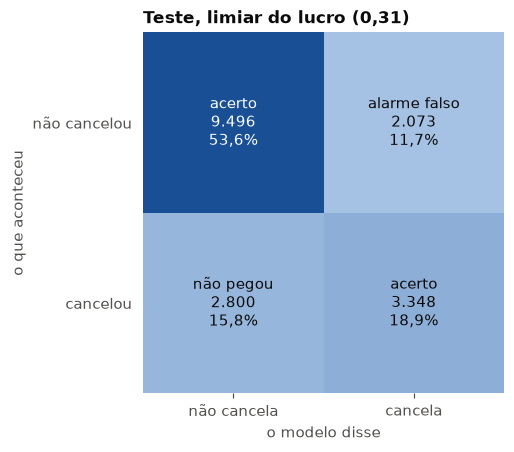

In [14]:
fig, ax = plt.subplots(figsize=(5.2, 4))
graficos.matriz_confusao(ax, confusion_matrix(y_teste, prob_teste >= melhor),
                         f"Teste, limiar do lucro ({melhor:.2f})".replace(".", ","))
fig.savefig("../figures/matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

Das 17.717 reservas do teste, o modelo acerta 72,5%: 9.496 que não cancelaram e 3.348 que cancelaram. Erra em 2.073 alarmes falsos (marcou, mas o hóspede veio) e em 2.800 cancelamentos que não pegou. No cenário de custo da 4.1, um alarme falso custa um contato (€30) e um cancelamento não pego é uma chance perdida de recuperar parte da reserva — por isso o limiar foi escolhido pelo lucro, e não pela acurácia.

## Resumo
- **Pergunta:** no momento da reserva, dá para saber quais vão cancelar? Em boa parte, sim.
- **Resultado (teste, mai–ago/2017):** das 10% reservas com maior risco, **67% a 73% cancelam de fato** (conservador e otimista), contra 35% sorteando e 54% com uma tabela de segmento × antecedência.
- **Taxa de acerto (teste, limiar do lucro 0,31):** acurácia de 72,5% (chutar que ninguém cancela já dá 65,3%), precisão de 62%, recall de 55% e F1 de 0,58.
- **O que mais pesa:** antecedência, pedidos especiais, agência e segmento.
- **Cuidado com vazamento:** 6 colunas da base contam a resposta e ficaram de fora; com elas o modelo pareceria muito melhor e seria inútil na prática.
- **Limitações:** 2 hotéis em Portugal, 2015–2017; cenário de custo suposto; pedidos especiais podem incluir pedidos feitos depois da reserva; probabilidades subestimadas quando a taxa de cancelamento sobe.